# 01 深度学习概述与 PyTorch 张量入门


本系列按课程 **day01—day07 共 7 篇**整理。本篇对应 day01：深度学习知识框架、简介与特点、常用模型、应用场景、发展史、PyTorch 框架，以及张量创建和元素类型转换。

资料：[深度学习神经网络课程资料](https://pan.baidu.com/s/1FPhKS2qMBgnqVOXCyhBTog?pwd=1234)，提取码 `1234`。

已核对 day01 的 12 个视频文件；其中两个文件使用“Day01-09”编号，分别讲全0/1/指定值张量和线性/随机张量，均纳入本篇。`课堂笔记.zip` 在线预览需要会员，本次下载也未取得文件，所以本篇按**已核对的视频目录**组织主题，补充独立编写、实际运行核对的 PyTorch 示例，不作为教师原文转录。视频未逐段转录。

沿用前面笔记的形式：全部为 Markdown 单元，Python 放在代码块中，按顺序复制到代码单元即可练习；全部示意图都嵌入当前 Notebook。本文只展开第1天内容，张量运算、索引、形状操作和自动微分将在第2篇学习。


## 本篇学习目标与7天安排

读完本篇，应能解释深度学习与机器学习的关系，辨认 ANN/CNN/RNN 的主要用途，理解张量的形状、元素类型和设备，并创建确定性或随机张量。

| 篇目 | 对应课程内容 |
| --- | --- |
| 01 / day01 | 深度学习概述、PyTorch入门、张量创建与类型转换 |
| 02 / day02 | 张量运算、索引、形状、拼接与自动微分入门 |
| 03 / day03 | 自动微分应用、线性回归、神经网络与激活函数 |
| 04 / day04 | 参数初始化、网络搭建与训练、损失函数、反向传播 |
| 05 / day05 | 优化器、学习率调整、Dropout、BatchNorm、分类案例数据准备 |
| 06 / day06 | ANN手机价格分类实战、图像基础、CNN卷积与池化 |
| 07 / day07 | CNN图像分类实战、词嵌入、RNN与AI歌词生成 |

本篇代码依赖 `torch`。自绘图已经内嵌，阅读不需要安装绘图工具。CPU 可以运行本篇全部例子；不需要先配置 GPU。


## 1. 人工智能、机器学习与深度学习

**人工智能（AI）**是研究和构建智能行为系统的广泛领域；**机器学习（ML）**是让系统从数据中学习规律的方法集合；**深度学习（DL）**主要用具有多层结构的神经网络学习表示和任务映射。

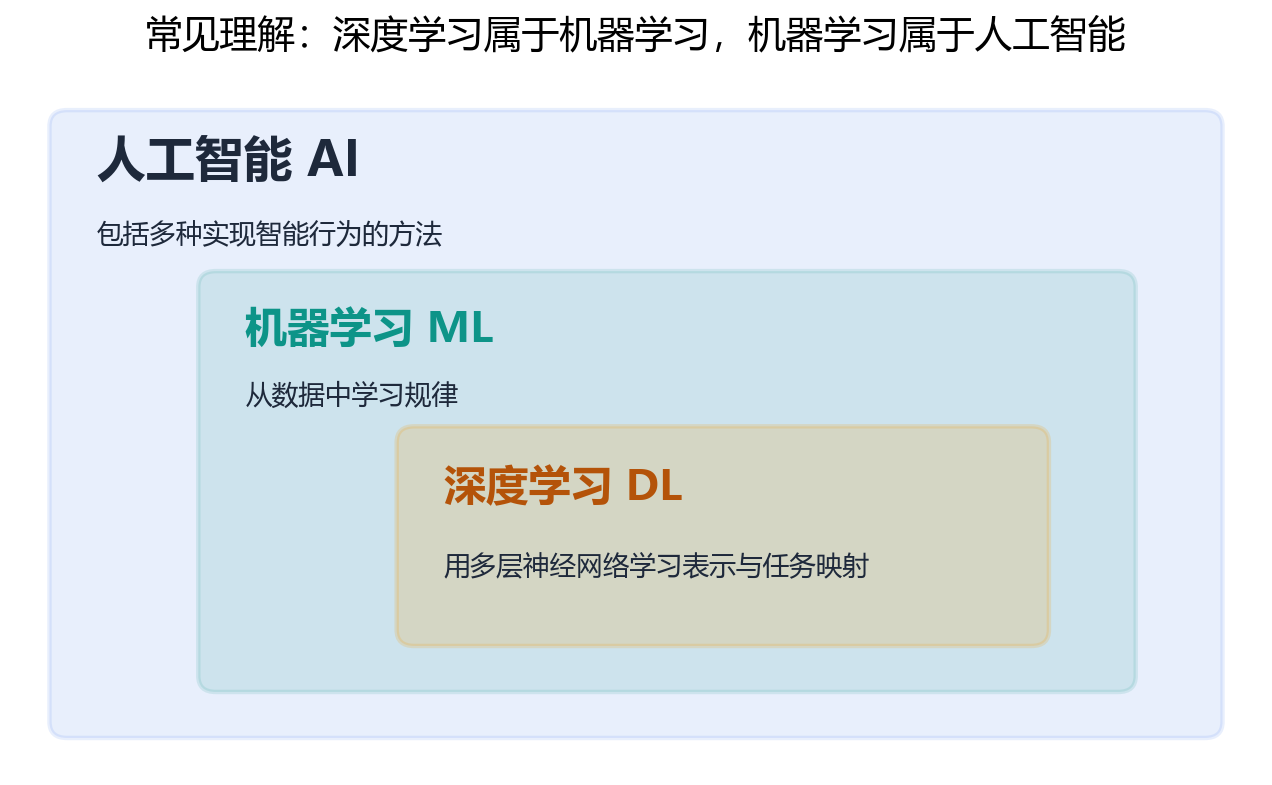

*本文自绘：表示常见的领域包含关系，不表示所有 AI 系统都必须使用深度学习。*

例如，规则专家系统可以属于 AI；线性回归、决策树、KMeans 属于机器学习；多层神经网络、CNN 和 RNN 是本课程要学习的神经网络模型。

与第05模块机器学习衔接时，可以这样理解：数据划分、目标定义、损失、泛化和评价仍然重要，变化主要在于模型结构、表示学习以及训练工具。


## 2. 神经网络为什么可以学习

一个神经元通常把输入加权求和，再通过激活函数：

$$z=\sum_{j=1}^{d}w_jx_j+b,\qquad a=\sigma(z)$$

多个神经元组成一层，多层逐级组合，得到从输入到输出的映射：

$$\hat y=f_\theta(x)$$

其中 $x$ 是输入，$\theta$ 表示需要学习的参数，$\hat y$ 是模型输出。损失函数比较预测与目标，优化器根据梯度更新参数；这些机制会在第3—5篇展开。

“深”通常指多层表示变换，而不是简单地指参数多、文件大或输入维度高。单层很宽的网络也可能有很多参数；更深的网络也不保证效果更好。

没有激活函数时，普通全连接仿射层连续堆叠仍等价于一个仿射变换。非线性使网络能够表达更复杂的关系。


## 3. 特征工程与表示学习

传统机器学习常由人先选取特征，例如历史负荷、小时、月份，再把特征交给回归器。深度学习可以从更接近原始形式的数据中逐层学习表示，例如图像中的边缘、纹理和更高层结构。

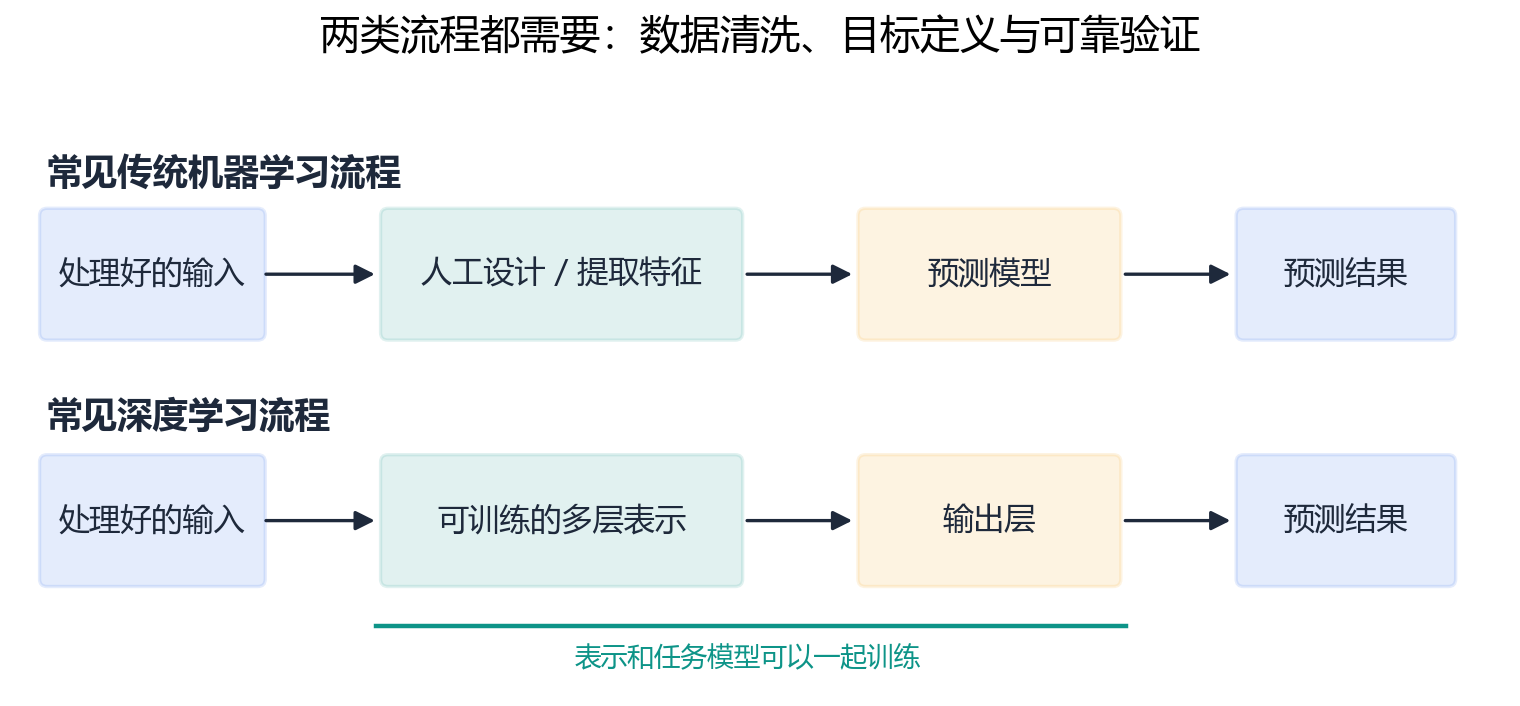

*本文自绘：突出特征表示与预测模型的关系；图中的表示不是每个网络必然学习到的固定阶段。*

| 对比项 | 常见传统机器学习流程 | 常见深度学习流程 |
| --- | --- | --- |
| 输入 | 经人工整理的特征表 | 特征表、图像、序列、文本编码等 |
| 特征 | 人工特征较多 | 许多表示可随任务一起训练 |
| 典型优势 | 结构化小中型数据常有较好成本效益 | 能处理高维输入和复杂表示 |
| 常见成本 | 特征制作与调参 | 数据、算力、网络设计与训练调试 |
| 判断依据 | 同样需要验证集与测试集 | 同样需要验证集与测试集 |

深度学习没有取消数据清洗、时间对齐、标签质量和业务知识。表格任务上，XGBoost 等方法可能更合适；不能仅凭“深度”二字决定模型。


## 4. 深度学习的特点与使用边界

- **表示学习：**可以把特征变换与任务目标联动训练，但输入处理和结构设计仍然影响结果。
- **端到端训练：**从定义好的输入训练到定义好的输出；数据采集、人工审核等外部环节并未因此消失。
- **高容量与非线性：**可以拟合复杂模式，也可能记住训练样本，产生过拟合。
- **可扩展计算：**许多计算适合 GPU 等设备；小例子在 CPU 上更方便，GPU 也存在显存和传输成本。
- **数据依赖：**规模、代表性、噪声与分布变化都影响泛化；预训练可以减少某些任务的新标注需求。

适不适合使用，需要同时考虑数据量、输入结构、基线表现、推理延迟、成本和可维护性。训练分数好不代表未来数据表现好，模型更大也不自动解决数据泄漏。

本课程将先掌握基本网络和训练流程，再用 ANN、CNN、RNN 三个案例连接具体任务。


## 5. 常见网络模型：先识别用途

| 模型 | 主要思路 | 常见任务 | 本课程位置 |
| --- | --- | --- | --- |
| ANN / 全连接网络 / MLP | 层间通过全连接变换组合特征 | 表格分类、回归 | 手机价格分类 |
| CNN | 用卷积核提取局部模式并共享参数 | 图像分类，也可用于序列等 | 图像分类 |
| RNN | 通过隐藏状态处理序列依赖 | 序列建模、文本生成 | AI歌词生成 |
| Transformer | 基于注意力组织上下文信息 | 文本、视觉和多模态任务 | 拓展认识，非本篇实战 |
| 自编码器 | 学习重建输入及中间表示 | 表示学习、压缩、异常检测 | 拓展认识 |
| GAN | 生成器与判别器对抗训练 | 数据生成与图像合成等 | 拓展认识 |

ANN 是人工神经网络的广义名称；课程实战里常用来指全连接网络。CNN、RNN 也属于人工神经网络，不能理解成三者完全互斥。

LSTM 和 GRU 是为处理序列学习问题设计的循环网络变体。模型可以混合组合；以上用途只是常见起点，不是严格限制。


## 6. 应用场景：把任务说清楚

| 场景 | 输入 | 目标 | 评价关注点 |
| --- | --- | --- | --- |
| 图像分类 | 图像像素 | 类别 | 准确率、各类别召回率、混淆矩阵 |
| 目标检测 | 图像 | 物体类别与位置 | 检测精度、漏检、定位误差 |
| 文本分类 | 文本的数值编码 | 类别 | 类别不平衡、误判成本 |
| 语言生成 | 上下文文本 | 后续词元或字符 | 质量、约束、任务正确性 |
| 语音处理 | 声学信号或特征 | 转写、识别或生成 | 转写错误与时延等 |
| 时间序列预测 | 历史序列及可用外部变量 | 未来数值 | MAE/RMSE、时间顺序验证 |
| 推荐 | 用户、内容与交互信息 | 排序或偏好分数 | 排序指标及真实业务效果 |

同一种输入可能对应不同任务：图像分类只输出类别，目标检测还输出位置；价格回归预测具体价格，手机价格分类预测价格档位。

模型只接受数字表示。文本需要编码，图像需要确定通道和尺寸，类别需要定义标签。输入格式错误时，训练框架不会替我们理解业务含义。


## 7. 发展脉络：算法、数据与计算共同推动

| 时间 | 代表事件 | 需要理解的变化 |
| --- | --- | --- |
| 1957—1958年前后 | 感知机提出与早期实现 | 早期可学习模型探索 |
| 1986年 | 反向传播被广泛推广用于多层网络 | 多层网络训练的重要进展；不是说此年首次发明链式法则 |
| 1998年 | LeNet-5 | 卷积网络用于字符识别 |
| 2006年前后 | 深层模型与逐层预训练研究 | 推动深层表示学习研究 |
| 2012年 | AlexNet 在 ImageNet 竞赛取得突破 | 大规模数据、GPU与训练技巧结合 |
| 2017年 | Transformer 提出 | 注意力成为重要模型结构 |
| 2020年代 | 大规模预训练与生成模型扩展 | 语言、视觉和多模态应用发展 |

这是补充的学习脉络，不是教师发展史视频的逐字转录。不能把深度学习的进步只归结于一个算法，也不能把今天常见的结构视为对所有任务的唯一选择。


## 8. PyTorch是什么

PyTorch 是用于张量计算和机器学习的开源框架，支持 CPU 和多种加速设备。本课程主要使用 Python 接口。

| 模块 | 用途 | 什么时候深入 |
| --- | --- | --- |
| `torch` | 张量创建、运算、设备与类型 | 本篇开始 |
| `torch.autograd` | 自动计算梯度 | 第2—3篇 |
| `torch.nn` | 网络层、模型模块和损失 | 第3—4篇 |
| `torch.optim` | 优化器与学习率调度 | 第5篇 |
| `torch.utils.data` | Dataset、DataLoader | 后续训练案例 |
| `torchvision` | 常见视觉工具、数据和变换 | CNN案例按需使用 |

PyTorch 常用动态图方式，前向计算发生时建立用于求导的计算图；现代版本也支持编译等功能。**本篇不需要开启编译，也不需要先掌握自动微分。**

PyTorch 负责数值计算与训练基础设施；它不会自动选标签、修复泄漏或判定哪种网络适合业务。


## 9. 环境准备与第一段代码

先使用 [PyTorch官方安装页面](https://pytorch.org/get-started/locally/) 选择操作系统、Python、安装方式和计算平台；GPU安装要匹配支持的驱动与运行环境。仅运行本篇可以选择 CPU。

在 Notebook 中安装时可使用 `%pip`，确保安装到当前内核对应的 Python；具体命令以官方页面当前选择为准。安装完成后，必要时重启内核。

```python
import torch

print("PyTorch版本：", torch.__version__)
print("CUDA可用：", torch.cuda.is_available())
print("默认浮点类型：", torch.get_default_dtype())

# 本篇明确用CPU，便于在普通电脑复现。
device = torch.device("cpu")
hello = torch.tensor([1, 2, 3], device=device)
print(hello)
print("shape =", hello.shape, "dtype =", hello.dtype, "device =", hello.device)
```

默认设置下，`hello` 是形状 `(3,)`、元素类型 `torch.int64` 的 CPU 张量。它包含三个整数，不是一个形状 `(1,3)` 的二维矩阵。

`torch.cuda.is_available()` 为 False 不影响本篇运行；它只说明当前环境无法使用 CUDA 接口，并不等同于对电脑全部硬件的检测。


## 10. 张量：多维数据的数值容器

本课程里的张量可以先理解为带有元素类型和设备信息的多维数组。张量不仅用来装训练数据，也用于参数、输出和中间结果。

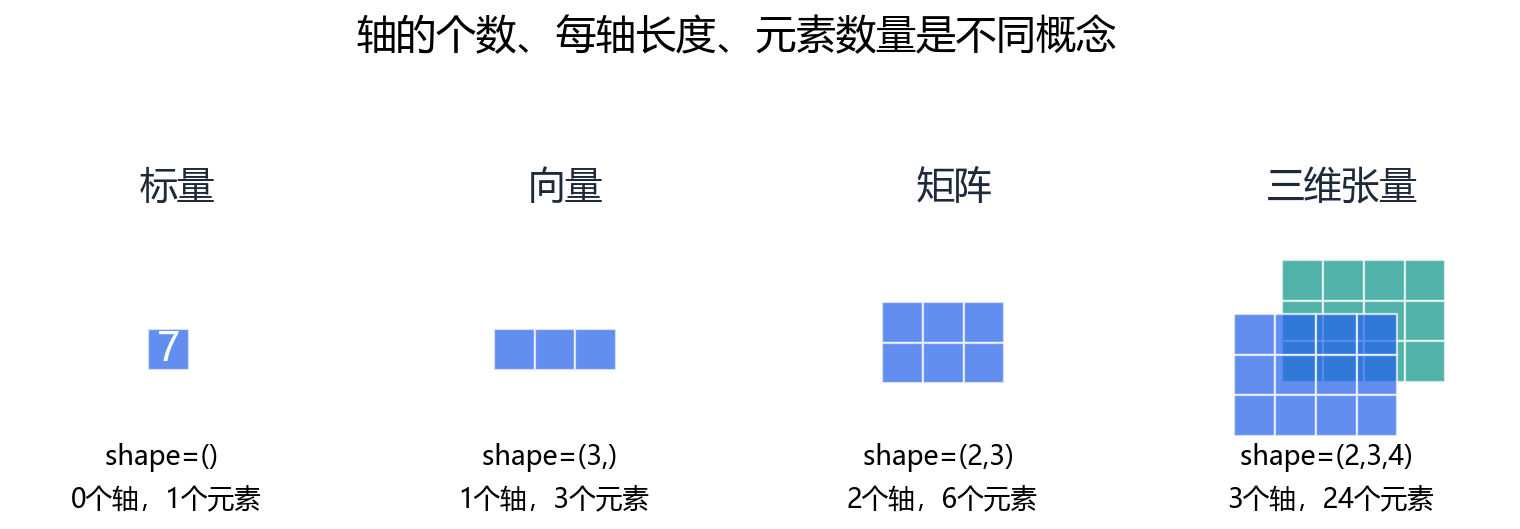

*本文自绘：三维例子形状为 `(2,3,4)`，共有24个元素；图中每块表示一个 `3×4` 切片。*

| 数据 | 形状示例 | 维数 / 轴数 | 元素数 |
| --- | --- | --- | --- |
| 标量 | `()` | 0 | 1 |
| 向量 | `(3,)` | 1 | 3 |
| 矩阵 | `(2,3)` | 2 | 6 |
| 三维张量 | `(2,3,4)` | 3 | 24 |

在数组语境里，“维数”指轴的个数。形状 `(2,3,4)` 是三维，不是四维，也不能把元素数24叫维数。数学中的张量概念更广，本篇先掌握 PyTorch 的数组用法。


## 11. 看懂shape、ndim、numel、dtype和device

```python
scalar = torch.tensor(7)
vector = torch.tensor([10, 20, 30])
matrix = torch.tensor([[1, 2, 3], [4, 5, 6]])
cube = torch.zeros((2, 3, 4))

for name, value in [
    ("标量", scalar), ("向量", vector),
    ("矩阵", matrix), ("三维张量", cube),
]:
    print(name, "shape:", tuple(value.shape), "ndim:", value.ndim,
          "numel:", value.numel(), "dtype:", value.dtype,
          "device:", value.device)

assert scalar.shape == torch.Size([])
assert scalar.ndim == 0 and scalar.numel() == 1
assert matrix.shape == torch.Size([2, 3]) and matrix.numel() == 6
assert cube.ndim == 3 and cube.numel() == 24
print("标量转成Python数字：", scalar.item())
```

- `shape` / `size()`：每个轴的长度。
- `ndim` / `dim()`：轴的个数。
- `numel()`：所有元素的数量，通常等于各轴长度的乘积。
- `dtype`：每个元素的类型，同一个普通张量内通常统一。
- `device`：数据所在的设备，例如 CPU 或 CUDA设备。

`item()` 只适用于恰好有一个元素的张量。一个元素并不意味着一定是0维，例如形状 `(1,)` 也只有一个元素，但它是1维。


## 12. 用torch.tensor从已有数字创建

`torch.tensor` 可以从 Python 数字、列表、嵌套列表等数据创建张量。默认设置下，整数列表通常推断成 `int64`，含浮点数的数据通常使用默认浮点类型 `float32`。

```python
integer_data = torch.tensor([1, 2, 3])
float_data = torch.tensor([1.0, 2.0, 3.0])
mixed_data = torch.tensor([1, 2.5, 3])
explicit_float = torch.tensor([[1, 2], [3, 4]], dtype=torch.float32)

print(integer_data, integer_data.dtype)
print(float_data, float_data.dtype)
print(mixed_data, mixed_data.dtype)
print(explicit_float, explicit_float.shape, explicit_float.dtype)

assert integer_data.dtype == torch.int64
assert float_data.dtype == torch.float32
assert mixed_data.dtype == torch.float32
assert explicit_float.shape == (2, 2)

original = [1.0, 2.0]
copied = torch.tensor(original)
original[0] = 99.0
assert copied[0].item() == 1.0
```

嵌套列表各行长度要一致，例如 `[[1,2],[3,4]]` 可以形成二维张量，`[[1,2],[3]]` 不能直接形成普通的规则二维张量。

`torch.tensor` 会复制数据。以后学习 `as_tensor`、`from_numpy` 时，要另外关注共享内存；不要把所有创建方法都理解成完全相同。


### 12.1 torch.Tensor与torch.tensor不要混淆

`torch.Tensor` 是张量类型，也保留了一些传统构造方式；`torch.tensor` 是根据传入数据创建张量的常用工厂函数。初学时建议优先使用后者，并显式指定关键类型。

```python
legacy_data = torch.Tensor([1, 2, 3])
modern_data = torch.tensor([1, 2, 3])
print("传统数据构造：", legacy_data.dtype)
print("常用数据构造：", modern_data.dtype)
assert legacy_data.dtype == torch.float32
assert modern_data.dtype == torch.int64
assert isinstance(modern_data, torch.Tensor)

# 传入尺寸，而不是传入元素：只分配空间，尚未初始化。
legacy_uninitialized = torch.Tensor(2, 3)
assert legacy_uninitialized.shape == (2, 3)
print("未初始化张量的形状：", legacy_uninitialized.shape)
```

上述默认类型结论以本篇未修改默认浮点类型、默认设备的环境为前提。`torch.Tensor(2,3)` 中的数字表示尺寸；不能误当作装有数值2和3的向量。需要明确表达意图时，用 `torch.empty((2,3))` 或 `torch.tensor([2,3])`。


## 13. 创建全0、全1和指定值张量

```python
zeros = torch.zeros((2, 3), dtype=torch.float32)
ones = torch.ones((2, 3), dtype=torch.float32)
filled = torch.full((2, 3), fill_value=5, dtype=torch.int64)
constant = torch.full((2, 3), fill_value=2.5, dtype=torch.float32)

print("全0：\n", zeros)
print("全1：\n", ones)
print("指定整数：\n", filled)
print("指定小数：\n", constant)
assert torch.equal(zeros, torch.tensor([[0., 0., 0.], [0., 0., 0.]]))
assert torch.equal(filled, torch.tensor([[5, 5, 5], [5, 5, 5]]))

# _like系列按照参考张量创建；需要不同类型时可显式覆盖。
reference = torch.tensor([[1, 2], [3, 4]], dtype=torch.int64)
same_shape_zeros = torch.zeros_like(reference)
same_shape_float = torch.ones_like(reference, dtype=torch.float32)
assert same_shape_zeros.shape == reference.shape
assert same_shape_zeros.dtype == torch.int64
assert same_shape_float.dtype == torch.float32
```

`zeros`、`ones` 默认使用浮点类型；`full` 在未指定dtype时也会参考填充值推断类型。因此正式代码最好显式写明 `dtype`，尤其不要因为填充值恰好为整数就意外生成整型输入。

`zeros_like` 等默认继承参考张量的形状、dtype与device，可显式覆盖；不要把它们理解成复制参考张量的原始数值。


### 13.1 empty不是全0，eye用于单位矩阵

```python
buffer = torch.empty((2, 3), dtype=torch.float32)
print("empty只检查形状：", buffer.shape)
# 未初始化内容不能作为输入使用；必须先给每个元素确定的值。
buffer.fill_(0)
assert torch.equal(buffer, torch.zeros((2, 3)))

identity = torch.eye(3, dtype=torch.float32)
print("单位矩阵：\n", identity)
assert torch.equal(identity, torch.tensor([
    [1., 0., 0.], [0., 1., 0.], [0., 0., 1.],
]))
```

`empty` 分配空间但没有赋予可依赖的初值；偶尔看见全0也不能保证下次仍是全0。`fill_` 末尾的下划线表示原地修改，更多原地操作与梯度注意事项将在后续学习。

`eye` 是补充创建方式，本篇只了解它生成对角线为1、其他位置为0的矩阵。


## 14. 等间隔数列：arange与linspace

| API | 控制参数 | 区间规则 | 适用例子 |
| --- | --- | --- | --- |
| `torch.arange(start,end,step)` | 步长 | 通常包含start，不包含end | 整数索引、固定步长 |
| `torch.linspace(start,end,steps)` | 元素数量 | steps≥2时包含两端点 | 固定采样数量 |
| `torch.logspace(start,end,steps,base)` | 指数两端和数量 | 在指数上等间隔，再取幂 | 跨数量级搜索，补充了解 |

```python
sequence = torch.arange(0, 10, 2)
five_points = torch.linspace(0, 1, steps=5)
log_points = torch.logspace(-2, 2, steps=5, base=10)

print("arange：", sequence)
print("linspace：", five_points)
print("logspace：", log_points)
assert torch.equal(sequence, torch.tensor([0, 2, 4, 6, 8]))
torch.testing.assert_close(five_points, torch.tensor([0., 0.25, 0.5, 0.75, 1.]))
torch.testing.assert_close(log_points, torch.tensor([0.01, 0.1, 1., 10., 100.]))
assert torch.linspace(2, 8, steps=1).item() == 2
assert torch.arange(0, 5).dtype == torch.int64
```

`linspace` 的 `steps` 是数量，不是步长。`arange` 采用小数步长时可能因浮点表示误差使边界和数量不如预期；需要准确控制数量时优先用 `linspace`。旧的 `torch.range` 已弃用，不建议作为新代码写法。


## 15. 随机张量：分布、区间与形状

| API | 分布或作用 | 关键规则 |
| --- | --- | --- |
| `torch.rand` | 标准均匀随机数 | 理想分布区间为 $[0,1)$ |
| `torch.randn` | 标准正态随机数 | 分布均值0、标准差1；单次小样本不一定如此 |
| `torch.randint` | 区间内随机整数 | 包含low，不包含high |
| `torch.randperm` | 随机排列 | 生成0到n-1的排列，每个数出现一次 |

```python
torch.manual_seed(42)
uniform = torch.rand((2, 3))
normal = torch.randn((2, 3))
integers = torch.randint(low=0, high=10, size=(2, 3))
permutation = torch.randperm(5)

print("均匀随机：\n", uniform)
print("正态随机：\n", normal)
print("随机整数：\n", integers)
print("随机排列：", permutation)
assert uniform.shape == (2, 3)
assert bool(((uniform >= 0) & (uniform < 1)).all())
assert bool(((integers >= 0) & (integers < 10)).all())
assert integers.dtype == torch.int64
assert sorted(permutation.tolist()) == [0, 1, 2, 3, 4]
```

`randn` 中的“n”可记为normal，不代表输出维数；输出形状由传入尺寸决定。`randint(0,10,...)` 不会生成10。随机排列和随机整数不同，后者允许重复。

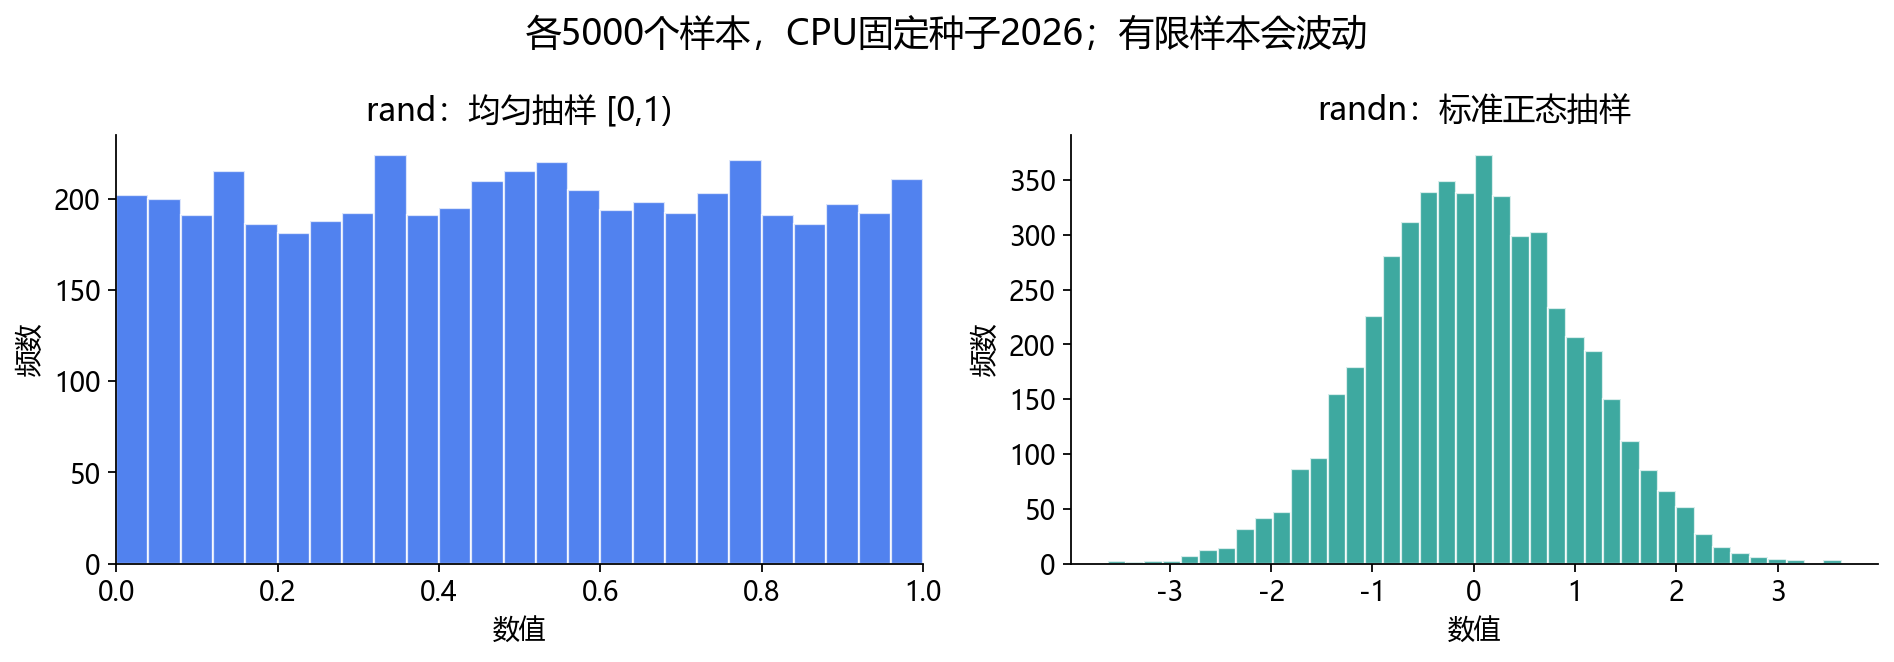

*本文自绘：各抽取5000个随机数，以直方图展示分布差别，固定种子便于复现。频数只代表这一次抽样，不能把曲线形状视为所有小样本必须满足的结果。*


### 15.1 随机种子与独立Generator

随机数通常来自伪随机数生成器。种子相同、运行环境和调用顺序相同，可以复现对应随机序列；连续两次抽样仍然会推进状态，不会自动返回相同结果。

```python
torch.manual_seed(2024)
sample_a = torch.rand(4)
sample_b = torch.rand(4)
torch.manual_seed(2024)
sample_a_again = torch.rand(4)
assert torch.equal(sample_a, sample_a_again)
print("重置种子后复现：", sample_a_again)
print("未重置时的下一批：", sample_b)

# 局部生成器，避免为这个小实验重置全局随机状态。
gen1 = torch.Generator(device="cpu").manual_seed(17)
gen2 = torch.Generator(device="cpu").manual_seed(17)
local_a = torch.randn((2, 3), generator=gen1)
local_b = torch.randn((2, 3), generator=gen2)
assert torch.equal(local_a, local_b)
```

固定种子有利于对比实验，但不保证不同PyTorch版本、设备或并行算法之间逐位一致。完整训练的可复现性还涉及数据加载和非确定性算子，这部分在训练案例中再展开。


## 16. 元素类型：整数、浮点和布尔

| dtype | 常见用途 | 需要注意 |
| --- | --- | --- |
| `torch.float32` | 常见网络输入、参数和输出 | 通常是默认浮点类型 |
| `torch.float64` | 某些高精度数值计算 | 存储通常更大，性能取决于设备 |
| `torch.float16` / `bfloat16` | 特定设备上的低精度计算 | 需要硬件与算子支持，不是初学时默认全改成它 |
| `torch.int64` | 整数、索引、某些分类标签 | 也称long |
| `torch.int32` | 某些整数数据 | 也称int，不同API可能要求不同类型 |
| `torch.bool` | 条件与掩码 | 表示True/False |

`dtype` 是每个元素的数据表示方式，`shape` 是组织方式，二者独立。例如 `(2,3)` 的张量可以是float32，也可以是int64；转类型通常不会改变形状。

网络的数值输入常用浮点数，但并不是“所有东西都转float”。例如后续 `CrossEntropyLoss` 的常见类别索引目标使用long；输入输出接口需要按具体API确认。


## 17. 类型转换：to、float、double、long和int

```python
source = torch.tensor([1.9, -2.9, 3.0], dtype=torch.float32)
as_long = source.long()
as_int = source.int()
as_double = source.double()
as_float = as_long.float()
via_to = source.to(dtype=torch.float64)
via_type = source.type(torch.float64)

print("原始：", source, source.dtype)
print("long：", as_long, as_long.dtype)
print("int：", as_int, as_int.dtype)
print("double：", as_double, as_double.dtype)
print("重新float：", as_float)
assert torch.equal(as_long, torch.tensor([1, -2, 3]))
assert as_int.dtype == torch.int32
assert as_double.dtype == torch.float64
assert via_to.shape == source.shape
assert source.dtype == torch.float32
torch.testing.assert_close(via_to, via_type)

needs_rounding = torch.tensor([1.6, -2.6])
rounded_then_integer = needs_rounding.round().long()
assert torch.equal(rounded_then_integer, torch.tensor([2, -3]))
```

浮点转整数通常**向零截断**，不是四舍五入：1.9变1，-2.9变-2。若确实需要先舍入，应明确调用舍入函数，再转换，并理解所用舍入规则。

`to` 或便捷转换方法不会原地改变原变量；若目标类型和设备已经一致，`to` 可能直接返回自身。不能一概认为“每次转换必然新复制一份”。

更高精度的类型不能恢复原先丢掉的信息：先从1.9转成1，再转回浮点得到1.0，不会变回1.9。


### 17.1 用一个例子理解float32的精度边界

浮点数表示精度有限，打印看似相同不等于任意小数都被精确存储。float32 有24位有效二进制精度，超过一定大小的整数也不能逐个精确区分。

```python
large_integer = torch.tensor([16777217], dtype=torch.int64)
low_precision = large_integer.float()
integer_again = low_precision.long()
print("原整数：", large_integer.item())
print("转float32后再转回：", integer_again.item())
assert integer_again.item() == 16777216

high_precision = large_integer.double()
assert high_precision.long().item() == 16777217
```

这个例子说明类型转换可能有信息损失，并不是说所有任务都要使用float64。神经网络训练中常用float32，在精度、显存和性能之间取舍；后续低精度训练还需要专门的方法。


## 18. device：类型与设备可以一起指定

```python
cpu_values = torch.tensor([1, 2, 3], dtype=torch.float32, device="cpu")
converted = cpu_values.to(device="cpu", dtype=torch.float64)
assert cpu_values.device.type == "cpu"
assert converted.dtype == torch.float64
assert converted.shape == cpu_values.shape
print(converted.device, converted.dtype)

# 若当前环境支持CUDA，可以单独练习搬运；本篇CPU验证不依赖此分支。
if torch.cuda.is_available():
    gpu_values = cpu_values.to("cuda")
    back_to_cpu = gpu_values.cpu()
    torch.testing.assert_close(back_to_cpu, cpu_values)
    print("CUDA搬运完成：", gpu_values.device)
else:
    print("本例使用CPU，CUDA分支未执行")
```

形状、dtype、device 是三个不同维度的信息。CPU张量和GPU张量之间的运算通常需要先统一设备；浮点输入与网络参数也需要匹配支持的类型。

张量从CPU复制到GPU有成本，GPU内存也有限。对本篇的小张量，使用GPU并不会自然带来明显收益。本篇实际验证以CPU为准，不宣称测试了CUDA分支。


## 19. 完整小练习：为三位用户构建数据

设三位用户各有四个数值特征。这里只学习创建、类型和形状，不提前做神经网络训练。数字是自定义的教学样例，不是真实用户数据。

```python
# 行表示用户，列表示四个特征。
features = torch.tensor([
    [0.2, 0.5, 0.8, 0.1],
    [0.4, 0.7, 0.3, 0.6],
    [0.9, 0.2, 0.4, 0.5],
], dtype=torch.float32)

# 三个类别索引，先认识数据形状；后续再学习损失函数接口。
labels = torch.tensor([0, 2, 1], dtype=torch.int64)
initial_scores = torch.zeros((3, 3), dtype=torch.float32)
example_weights = torch.randn(
    (4, 3), generator=torch.Generator().manual_seed(8),
    dtype=torch.float32,
)

assert features.shape == (3, 4)
assert labels.shape == (3,)
assert initial_scores.shape == (3, 3)
assert example_weights.shape == (4, 3)
print("输入：", features.shape, features.dtype)
print("类别索引：", labels.shape, labels.dtype)
print("示意权重：", example_weights.shape)
```

三行输入对应三个标签，标签不是自动扩成 `(3,3)`。这里的正态随机权重只用于创建练习，不能代替后续课程里根据网络结构选择初始化方法。


## 20. 张量创建方法速查

| 需求 | 推荐写法 | 关键检查 |
| --- | --- | --- |
| 已有数值列表 | `torch.tensor(data,dtype=...)` | 数据形状规则、类型明确 |
| 全0 | `torch.zeros(size)` | size是形状 |
| 全1 | `torch.ones(size)` | 默认浮点类型 |
| 全部为指定值 | `torch.full(size,value)` | 最好明确dtype |
| 未初始化空间 | `torch.empty(size)` | 使用前写入所有元素 |
| 参考张量形状 | `zeros_like / ones_like / full_like` | 继承哪些属性，是否需要覆盖 |
| 对角线为1 | `torch.eye(n)` | 矩阵尺寸 |
| 按步长生成 | `torch.arange(start,end,step)` | 终点不包含、小数误差 |
| 按数量生成 | `torch.linspace(start,end,steps)` | steps是个数 |
| 均匀随机小数 | `torch.rand(size)` | $[0,1)$ |
| 正态随机小数 | `torch.randn(size)` | 小样本不保证均值0 |
| 随机整数 | `torch.randint(low,high,size)` | high不包含 |
| 随机排列 | `torch.randperm(n)` | 0到n-1，无重复 |

写每个张量前先回答四个问题：**需要什么数值、需要什么形状、需要什么类型、放在哪个设备。**创建完检查这四项，比只看打印出来的元素更可靠。


## 21. 常见错误与处理

| 容易混淆的地方 | 正确理解 |
| --- | --- |
| 深度学习等于所有人工智能 | 深度学习是AI中的一种重要技术路线 |
| 模型深就一定更好 | 需要同任务、同数据条件下比较验证表现 |
| 深度学习不需要特征或清洗 | 输入表示、清洗、标签和业务定义仍然重要 |
| 一个元素一定是0维 | `()` 与 `(1,)` 不同，元素数都可为1 |
| `(2,3,4)` 是4维 | 它有3个轴，共24个元素 |
| Tensor与tensor完全相同 | 类型、传统构造方式和常用工厂函数要区分 |
| empty默认都是0 | 未初始化，不可依赖其内容 |
| linspace的steps是步长 | steps是生成元素数量 |
| randint包含high | high不包含 |
| randn只能生成正数 | 正态随机数通常有正有负 |
| 小样本randn均值必为0 | 0是分布的期望，不是每次抽样的必然均值 |
| long会四舍五入 | 一般向零截断；需要舍入先明确处理 |
| 转成float64能恢复之前精度 | 已丢失的信息不能自动恢复 |
| 没有CUDA就无法学PyTorch | 本篇全部例子CPU即可运行 |
| 固定种子跨平台永远逐位一致 | 还受版本、设备和算法影响 |

后续写代码遇到异常时，优先打印 `shape`、`dtype` 和 `device`，再检查API要求；不要先盲目把数据全部reshape或转float。


## 22. 练习与参考答案

1. 创建一个 `(2,4)` 的float32张量，所有元素为3.5。  
   **答：**`torch.full((2,4),3.5,dtype=torch.float32)`。

2. 创建包含0、2、4、6、8的整数序列。  
   **答：**`torch.arange(0,10,2)`；终点10不包含。

3. 在-1到1之间取5个等间隔点。  
   **答：**`torch.linspace(-1,1,steps=5)`，结果为-1、-0.5、0、0.5、1。

4. 形状 `(8,3,32,32)` 有几个轴、多少元素？  
   **答：**4个轴，24576个元素。在常见图像约定下可能表示batch、通道、高、宽，但张量本身不会自动赋予这些含义。

5. `torch.tensor([2.9,-2.9]).long()` 是多少？  
   **答：**2与-2，向零截断。

6. 若只需要读取现有列表中的整数，如何避免误用传统float构造？  
   **答：**优先用 `torch.tensor(data,dtype=torch.int64)`，再检查dtype。

```python
answer1 = torch.full((2, 4), 3.5, dtype=torch.float32)
answer2 = torch.arange(0, 10, 2)
answer3 = torch.linspace(-1, 1, steps=5)
answer4 = torch.empty((8, 3, 32, 32))
answer5 = torch.tensor([2.9, -2.9]).long()
assert answer1.shape == (2, 4) and answer1.dtype == torch.float32
assert bool(answer1.eq(3.5).all())
assert torch.equal(answer2, torch.tensor([0, 2, 4, 6, 8]))
torch.testing.assert_close(answer3, torch.tensor([-1., -0.5, 0., 0.5, 1.]))
assert answer4.ndim == 4 and answer4.numel() == 24576
assert torch.equal(answer5, torch.tensor([2, -2]))
print("基础练习检查通过")
```

这些例子只检查小张量的创建与类型，不需要下载数据集，也没有训练成绩。


## 23. 来源与验证范围

课程依据为网盘 `04_深度学习神经网络/视频/day01` 的12个视频文件标题：知识框架、简介、特点、常用模型、应用场景、发展史、PyTorch框架、基本张量创建、全0/1/指定值、线性与随机张量、类型转换和创建总结。原 `课堂笔记.zip` 与 `课件.zip` 未读取内容，未把网络受限的资料伪装成教师原文。

补充参考：[PyTorch张量文档](https://docs.pytorch.org/docs/stable/tensors.html)、[PyTorch API文档](https://docs.pytorch.org/docs/stable/torch.html)、[PyTorch可复现性说明](https://docs.pytorch.org/docs/stable/notes/randomness.html)。这些链接供进一步查阅；本篇API行为由实际CPU运行核对。

本篇验证包括 Notebook格式、单元ID、全部Python代码块顺序运行、形状与元素数、数值和类型、随机数区间与种子复现、浮点转整数和精度例子、图片附件解码及HTML预览。CUDA分支未在本篇CPU环境执行；图全部为本文自绘，不是课程截图。

下一篇按day02继续：张量与NumPy转换、运算、索引、形状转换、拼接和自动微分。

本次验证环境：Python 3.13.7、PyTorch 2.14.1+cpu、CPU。顺序执行 14 个Python代码块通过，4张图片均为附件。
